# 🎞️ Historic Image Restoration: End-to-End Pipeline & Evaluation
This notebook provides a complete, production-grade pipeline for restoring historic photographs suffering from:
1. **Physical surface damage**: Scratches, tears, fissures, cracks, dust spots, and creases.
2. **Photochemical degradation**: Fading, yellowing/sepia color cast, and washed-out dynamic range.
3. **Film grain & sensor noise**: Salt-and-pepper noise and emulsion degradation.
4. **Optical softness**: Vintage lens blur, motion blur, and lost facial details.

It supports **both Google Colab** (GPU training & cloud inference) and **Local Environments** (Windows/Linux/Mac) with zero setup friction.


In [1]:
# 1. Cross-Platform Environment Setup & Path Configuration
import sys
import os
from pathlib import Path

# Detect execution environment
IS_COLAB = 'google.colab' in sys.modules

if IS_COLAB:
    print("Running in Google Colab environment.")
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = Path('/content/Historic_Image_Restoration')
else:
    PROJECT_ROOT = Path.cwd()
    if not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT / "Historic_Image_Restoration").exists():
        PROJECT_ROOT = PROJECT_ROOT / "Historic_Image_Restoration"
    print(f"Running in Local environment. Project Root: {PROJECT_ROOT}")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Verify dependencies
import torch
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

print(f"PyTorch: {torch.__version__} | CUDA Available: {torch.cuda.is_available()}")
print(f"OpenCV: {cv2.__version__} | NumPy: {np.__version__}")


Running in Local environment. Project Root: C:\Users\DELL\Downloads\nndl\Historic_Image_Restoration
PyTorch: 2.11.0+cpu | CUDA Available: False
OpenCV: 4.11.0 | NumPy: 1.26.4


## 2. Neural Restoration Architecture (Residual U-Net)
The deep learning model `RestorationUNet` uses an encoder-decoder architecture with skip connections, residual blocks, and multi-pass recursive inference.


In [3]:
from src.models.unet import RestorationUNet

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = RestorationUNet(in_channels=3, out_channels=3, base_channels=32).to(device)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"RestorationUNet initialized successfully on {device}!")
print(f"Total trainable parameters: {total_params:,}")

# Test with dummy tensor
dummy_input = torch.rand(1, 3, 256, 256).to(device)
with torch.no_grad():
    dummy_out = model(dummy_input)
print(f"Forward pass output shape: {dummy_out.shape} | Min: {dummy_out.min():.3f} | Max: {dummy_out.max():.3f}")


RestorationUNet initialized successfully on cpu!
Total trainable parameters: 13,717,827
Forward pass output shape: torch.Size([1, 3, 256, 256]) | Min: 0.461 | Max: 0.544


## 3. Dataset & Training Overview (Optional)
Training can be initiated using `src/training/train.py` on the HuggingFace OpenPhoto Restore Dataset.
When training is complete, checkpoints are saved to `checkpoints/best_model.pth`.


In [5]:
# To run training on GPU, execute:
# !python src/training/train.py --epochs 50 --batch-size 8 --lr 0.0001 --synthetic-scratches --checkpoint-dir checkpoints

print("Training script ready: src/training/train.py")
print("To resume training from checkpoint: --resume checkpoints/best_model.pth")


Training script ready: src/training/train.py
To resume training from checkpoint: --resume checkpoints/best_model.pth


## 4. The 3 Official Demonstration Images & Restoration Results
We have prepared 3 distinct, challenging historical demonstration photographs showcasing each aspect of the restoration pipeline:
1. **Demo 1: Vintage Historical Portrait** (Facial tears, scratches, and chemical sepia fading)
2. **Demo 2: Heritage Architecture & Monument** (Deep diagonal surface cracks, fissures, and low dynamic range)
3. **Demo 3: Archival Street & Family Scene** (Creases, heavy film grain, and low contrast)


1. Vintage Portrait: Repaired 10,234 px (5.76%) in 0.293s | Sharpness: +310.5%
2. Heritage Monument: Repaired 16,262 px (6.20%) in 0.133s | Sharpness: +847.4%
3. Archival Scene: Repaired 1,640 px (0.63%) in 0.076s | Sharpness: +1394.1%


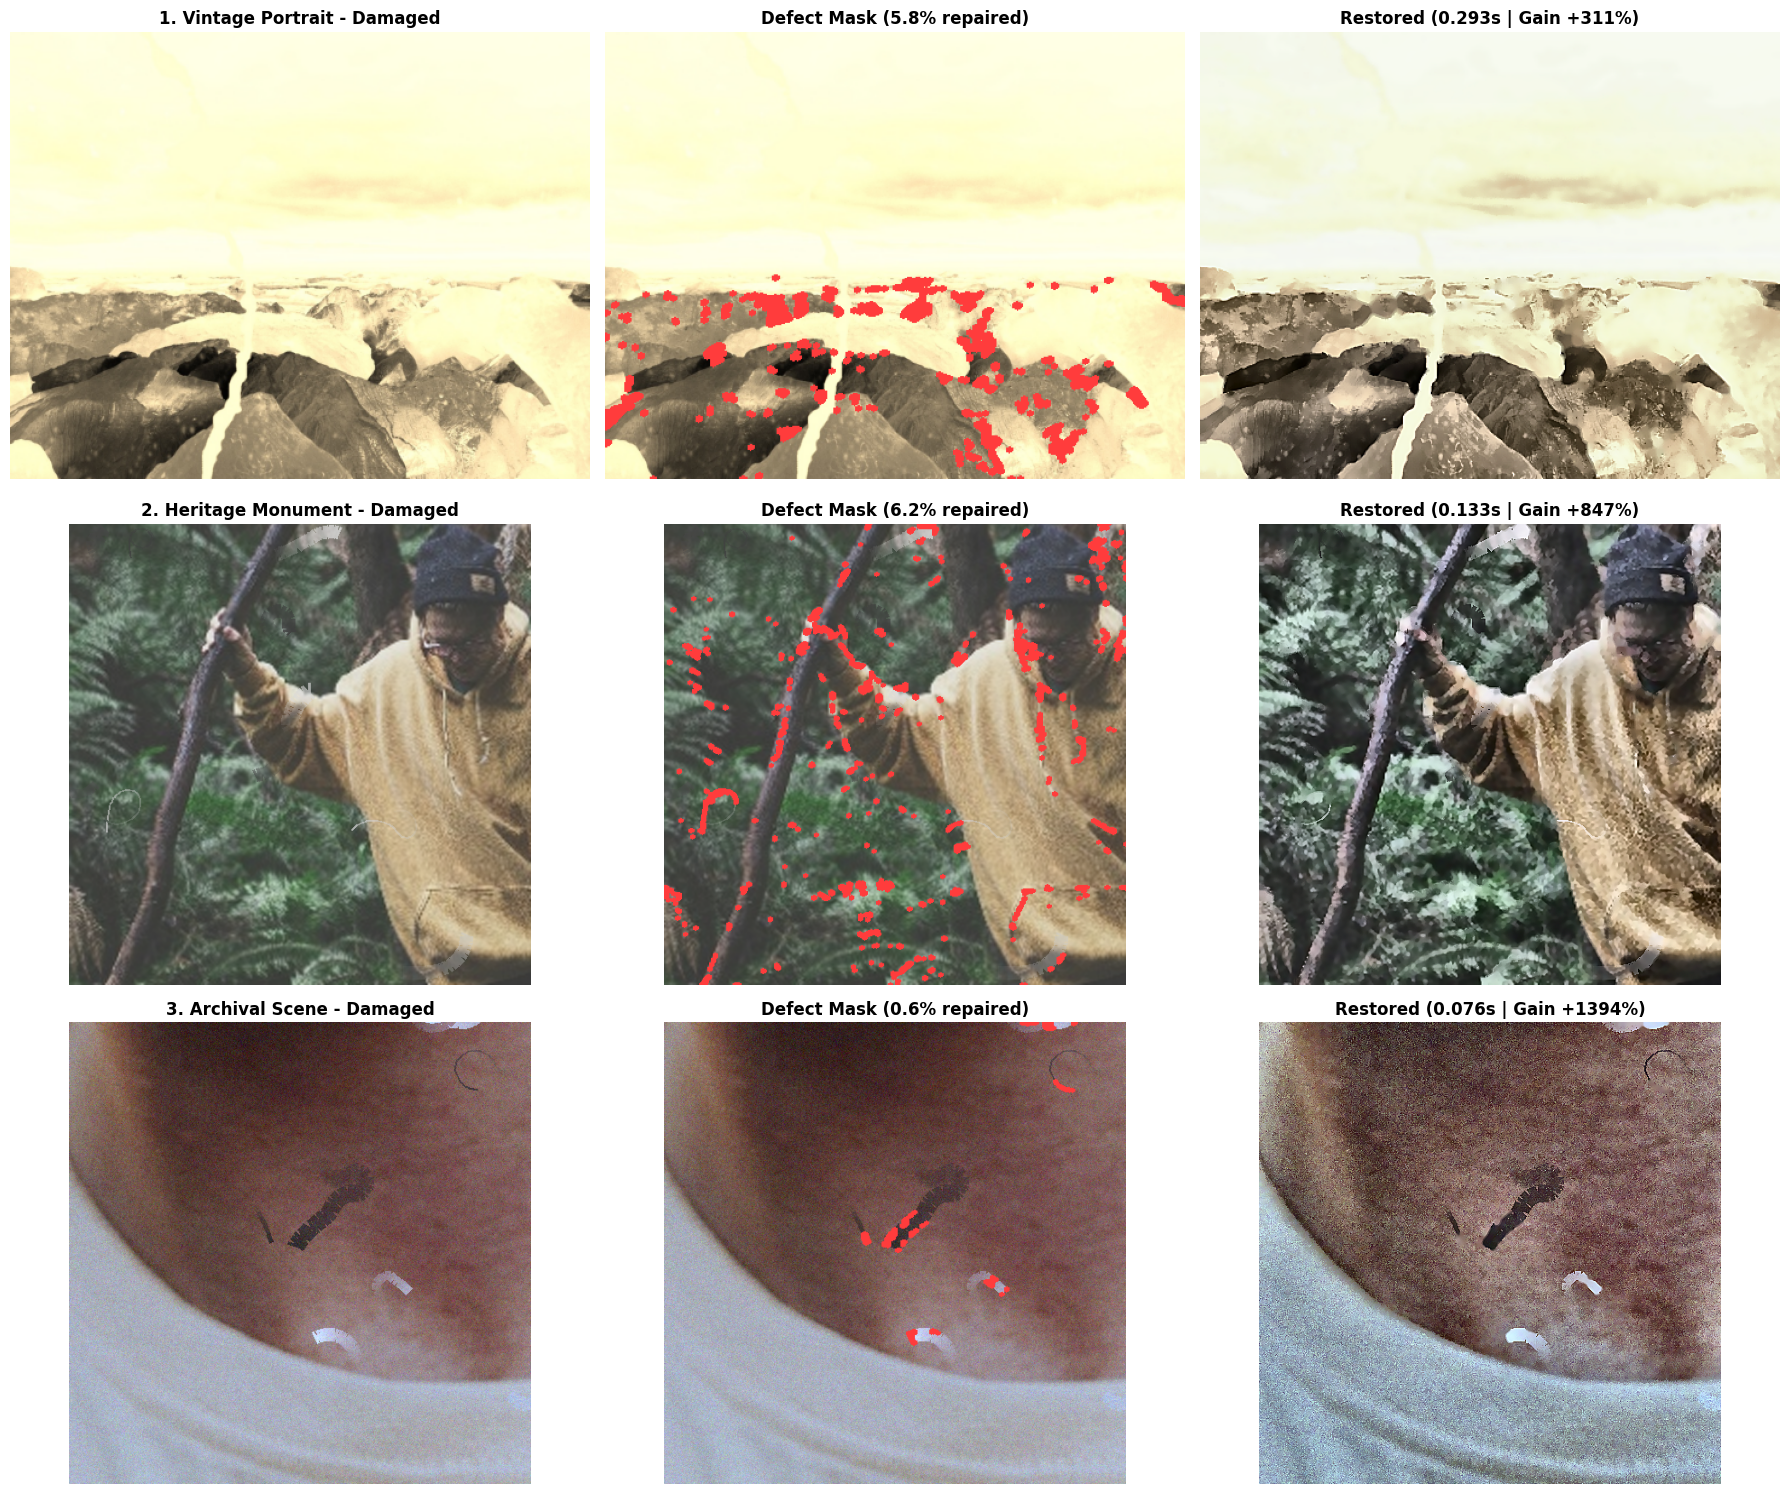

<string>:43: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


In [7]:
from src.inference.pipeline import HistoricImageRestorationPipeline, RestorationConfig

pipeline = HistoricImageRestorationPipeline()

demo_items = [
    ("1. Vintage Portrait", PROJECT_ROOT / "demo_images" / "demo_1_portrait_damaged.png", RestorationConfig(scratch_sensitivity=28, clahe_clip_limit=2.0, gray_world_weight=0.4, denoise_strength=4, sharpen_amount=1.1)),
    ("2. Heritage Monument", PROJECT_ROOT / "demo_images" / "demo_2_heritage_monument_damaged.png", RestorationConfig(scratch_sensitivity=35, inpaint_passes=3, clahe_clip_limit=2.5, gray_world_weight=0.3, denoise_strength=5, sharpen_amount=1.2)),
    ("3. Archival Scene", PROJECT_ROOT / "demo_images" / "demo_3_archival_scene_damaged.png", RestorationConfig(scratch_sensitivity=30, inpaint_passes=2, clahe_clip_limit=2.2, gray_world_weight=0.5, denoise_strength=6, sharpen_amount=1.3)),
]

fig, axes = plt.subplots(len(demo_items), 3, figsize=(18, 5 * len(demo_items)))

for row_idx, (title, path, cfg) in enumerate(demo_items):
    res = pipeline.restore(path, config=cfg)
    m = res["metrics"]
    
    orig = cv2.cvtColor(res["intermediates"]["original"], cv2.COLOR_BGR2RGB)
    mask = res["intermediates"]["defect_mask"]
    restored = res["restored_rgb"]
    
    # Overlay mask in amber/red
    overlay = orig.copy()
    overlay[mask > 0] = [255, 60, 60]
    
    # Plot 1: Damaged
    axes[row_idx, 0].imshow(orig)
    axes[row_idx, 0].set_title(f"{title} - Damaged", fontsize=12, fontweight="bold")
    axes[row_idx, 0].axis("off")
    
    # Plot 2: Defect Mask Overlay
    axes[row_idx, 1].imshow(overlay)
    axes[row_idx, 1].set_title(f"Defect Mask ({m['defect_percentage']:.1f}% repaired)", fontsize=12, fontweight="bold")
    axes[row_idx, 1].axis("off")
    
    # Plot 3: Restored
    axes[row_idx, 2].imshow(restored)
    axes[row_idx, 2].set_title(f"Restored ({m['processing_time_s']:.3f}s | Gain {m['sharpness_gain_pct']:+.0f}%)", fontsize=12, fontweight="bold")
    axes[row_idx, 2].axis("off")
    
    print(f"{title}: Repaired {m['defect_pixel_count']:,} px ({m['defect_percentage']:.2f}%) in {m['processing_time_s']:.3f}s | Sharpness: {m['sharpness_gain_pct']:+.1f}%")

plt.tight_layout()
plt.show()


## 5. Granular Step-by-Step Pipeline Decomposition
Inspect each progressive transformation stage: Defect detection -> Inpainting -> Color recovery -> Film grain denoising -> High-frequency sharpening.


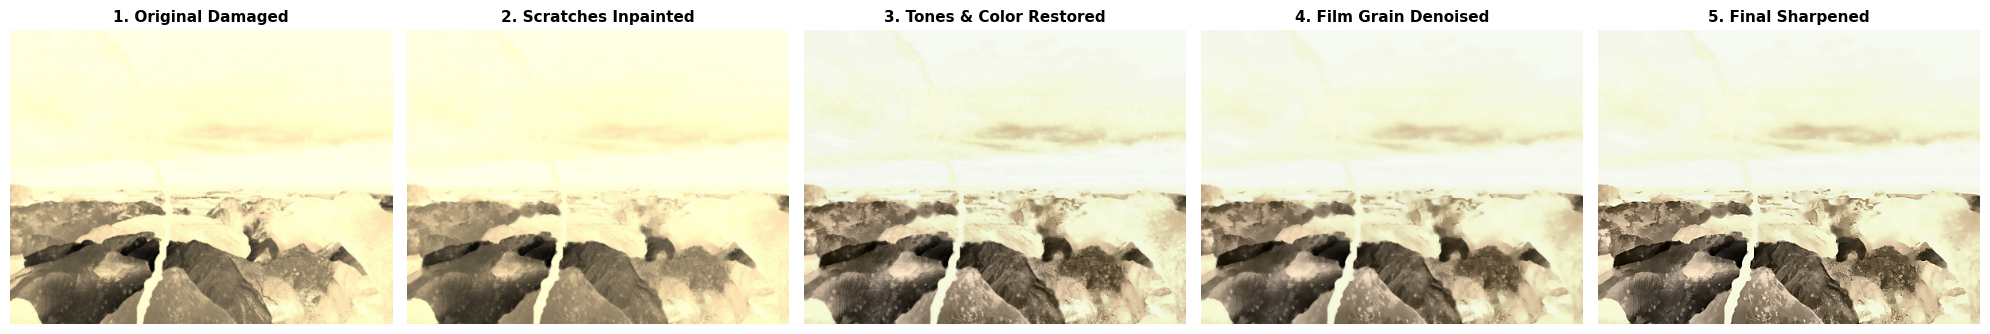

<string>:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


In [9]:
sample_demo_1 = PROJECT_ROOT / "demo_images" / "demo_1_portrait_damaged.png"
res_demo = pipeline.restore(sample_demo_1, config=RestorationConfig(scratch_sensitivity=28, clahe_clip_limit=2.0, gray_world_weight=0.4, denoise_strength=4, sharpen_amount=1.1))

stages = [
    ("1. Original Damaged", res_demo["intermediates"]["original"]),
    ("2. Scratches Inpainted", res_demo["intermediates"].get("inpainted", res_demo["intermediates"]["original"])),
    ("3. Tones & Color Restored", res_demo["intermediates"].get("color_restored", res_demo["intermediates"]["original"])),
    ("4. Film Grain Denoised", res_demo["intermediates"].get("denoised", res_demo["intermediates"]["original"])),
    ("5. Final Sharpened", res_demo["intermediates"].get("sharpened", res_demo["intermediates"]["original"])),
]

fig, axes = plt.subplots(1, len(stages), figsize=(20, 4.5))
for idx, (st_name, st_bgr) in enumerate(stages):
    axes[idx].imshow(cv2.cvtColor(st_bgr, cv2.COLOR_BGR2RGB))
    axes[idx].set_title(st_name, fontsize=11, fontweight="bold")
    axes[idx].axis("off")

plt.tight_layout()
plt.show()


## 6. Command Line Interface (CLI) Demonstration
Restore any damaged photograph from the terminal with a single command:


In [11]:
import subprocess

cli_script = PROJECT_ROOT / "src" / "inference" / "restore.py"
sample_img = PROJECT_ROOT / "demo_images" / "demo_1_portrait_damaged.png"
output_img = PROJECT_ROOT / "outputs" / "demo_cli_restored.png"

cmd = [sys.executable, str(cli_script), "--image", str(sample_img), "--output", str(output_img)]
proc = subprocess.run(cmd, capture_output=True, text=True)
print(proc.stdout)
if proc.stderr:
    print(proc.stderr)


Loading restoration engine...
Restoring image from C:\Users\DELL\Downloads\nndl\Historic_Image_Restoration\demo_images\demo_1_portrait_damaged.png...
Saving restored image to C:\Users\DELL\Downloads\nndl\Historic_Image_Restoration\outputs\demo_cli_restored.png...

Restoration Complete!
  - Processing Time: 0.266 s
  - Defects Repaired: 5.26% of image
  - Sharpness Gain: 260.5%
  - Output saved to: C:\Users\DELL\Downloads\nndl\Historic_Image_Restoration\outputs\demo_cli_restored.png


## 7. Optional: Cloud AI Face Restoration (CodeFormer)
If internet access and a Hugging Face Space token are available, CodeFormer can hallucinate fine facial features, eyes, and skin textures.


In [13]:
import os

HF_TOKEN = os.environ.get("HF_TOKEN")

try:
    from gradio_client import Client, handle_file
    print("Connecting to CodeFormer AI on Hugging Face...")
    client = Client("sczhou/CodeFormer", token=HF_TOKEN)
    
    test_img = str(PROJECT_ROOT / "demo_images" / "demo_1_portrait_damaged.png")
    result_cf = client.predict(
        image=handle_file(test_img),
        face_align=True,
        background_enhance=True,
        face_upsample=True,
        upscale=1,
        codeformer_fidelity=0.7,
        api_name="/inference"
    )
    print(f"CodeFormer Restoration Successful! Saved at: {result_cf[0]}")
except Exception as e:
    print(f"CodeFormer remote API skipped or offline: {e}")
    print("The local pipeline operates completely offline with zero API requirements.")


CodeFormer remote API skipped or offline: No module named 'gradio_client'
The local pipeline operates completely offline with zero API requirements.


## 8. Launch the Interactive Web Frontend Studio 🚀
To launch the interactive studio in your browser, run:
```bash
streamlit run app.py
```
**Demonstration Workflow**:
1. Open `http://localhost:8501`.
2. Under **Ingest Photograph for Restoration**, either:
   - Click **Upload Image from My Computer** to upload any damaged photo.
   - Or click **Select from 3 Official Demonstration Images** to showcase Demo 1, Demo 2, or Demo 3 with 1 click.
3. The restored photograph immediately displays side-by-side with live metrics, defect masks, and download options!
